# 02 — Windowing and feature construction

**Purpose.** Inspect the recorded feature definitions and window settings. Window size is a
sensitivity axis, not a tuned parameter.

**Inputs** `configs/evaluation_settings.json`, `configs/frozen_specs/`.

**Outputs** none. This notebook describes and inspects the representations; it does not
extract features or train models. The public package supports inspection of saved artifacts,
not a complete reconstruction from raw data.


In [1]:
import os, sys
from pathlib import Path
if 'google.colab' in sys.modules:
    from google.colab import drive; drive.mount('/content/drive')
    os.environ.setdefault('PROVICS_ROOT', '/content/drive/MyDrive/provics-recording-aware-evaluation')
else:
    os.environ.setdefault('PROVICS_ROOT', str(Path.cwd().parent))
sys.path.insert(0, os.environ['PROVICS_ROOT'])
from src.utils.paths import project_root
ROOT = project_root(); print('Project folder:', ROOT.name)

# Render compact, readable tables below each cell.
from IPython.display import display
import pandas as pd
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)


Project folder: code


In [2]:
from src.evaluation.replay import load_settings
settings = load_settings()
w = settings['windowing']
print('window durations (s)      :', w['durations_seconds'])
print('grid                      :', w['grid'])
print('aggregation               :', w['aggregation'])
print('same-recording buffer (s) :', w['same_recording_background_buffer_seconds'])
print('buffer scaling            :', w['buffer_scaling'])
print()
print('The buffer is held at 300 s in SECONDS across all window sizes, so a 5 s and a 60 s',
      'grid exclude the same amount of wall-clock time around each labeled action.')


window durations (s)      : [5, 10, 30, 60]
grid                      : epoch-aligned, non-overlapping
aggregation               : within-window only
same-recording buffer (s) : 300
buffer scaling            : seconds, held constant across window durations

The buffer is held at 300 s in SECONDS across all window sizes, so a 5 s and a 60 s grid exclude the same amount of wall-clock time around each labeled action.


In [3]:
# What each view contributes. Counts, rates and entropies - never raw identifiers.
for view, spec in settings['modalities'].items():
    if not isinstance(spec, dict) or 'availability_pct' not in spec:
        continue
    print(f"{view}  {spec['name']:<38} {spec['source_format']:<28} available {spec['availability_pct']}%")
print()
print('availability denominator:', settings['modalities']['availability_denominator'])
print()
print('M3 note:', settings['modalities']['M3']['reduced_input_note'])
display(pd.DataFrame([{'View': view, 'Evidence': spec['name'], 'Availability (%)': spec['availability_pct']} for view, spec in settings['modalities'].items() if isinstance(spec, dict) and 'availability_pct' in spec]))


M1  supervisory-host provenance            event/provenance graph       available 94.9%
M2  PLC/controller provenance              event/provenance graph       available 77.6%
M3  decoded Modbus protocol semantics      protocol-event sequence      available 94.9%
M4  physical-process telemetry             22-variable time series, 1 Hz available 98.7%

availability denominator: fraction of the aligned 60-s master grid for which the view is present

M3 note: The released records contain no register-value field.


,View,Evidence,Availability (%)
0,M1,supervisory-host provenance,94.9
1,M2,PLC/controller provenance,77.6
2,M3,decoded Modbus protocol semantics,94.9
3,M4,physical-process telemetry,98.7


In [4]:
# Feature families actually used, taken from the frozen post-screening list.
import json, re, collections
listing = json.loads((ROOT / 'configs/frozen_specs/feature_lists_post_screening.json').read_text())
for key in sorted(k for k in listing if k != '_meta'):
    print(f"{key:<9} {listing[key]['n_features']:>5} features")
print()
sample = listing['M3_w60']['features']
print('example M3 columns:', sample[:8])


M1_w10      180 features
M1_w30      180 features
M1_w5       180 features
M1_w60      180 features
M2_w10       98 features
M2_w30       98 features
M2_w5        98 features
M2_w60       98 features
M3_w10       48 features
M3_w30       48 features
M3_w5        48 features
M3_w60       48 features
M4_w10      199 features
M4_w30      199 features
M4_w5       199 features
M4_w60      199 features

example M3 columns: ['m3_n', 'm3_req', 'm3_resp', 'm3_n_client_ports', 'm3_n_units', 'm3_n_distinct_reg', 'm3_reg_min', 'm3_reg_max']


In [5]:
# Window size changes the aggregation only; the feature definitions are identical at every
# resolution. That is what makes the four grids comparable re-aggregations rather than four
# separate experiments.
widths = {k: v['n_features'] for k, v in listing.items() if k != '_meta'}
for view in ('M1','M2','M3','M4'):
    sizes = {k.split('_w')[1]: v for k, v in widths.items() if k.startswith(view)}
    print(f'{view}: ', sizes, '<- identical width at every window size' if len(set(sizes.values()))==1 else '<- DIFFERS')
feature_counts = pd.DataFrame([{'View': key.split('_w')[0], 'Window (s)': int(key.split('_w')[1]), 'Features': value} for key, value in widths.items()]).pivot(index='View', columns='Window (s)', values='Features')
display(feature_counts)


M1:  {'5': 180, '10': 180, '30': 180, '60': 180} <- identical width at every window size
M2:  {'5': 98, '10': 98, '30': 98, '60': 98} <- identical width at every window size
M3:  {'5': 48, '10': 48, '30': 48, '60': 48} <- identical width at every window size
M4:  {'5': 199, '10': 199, '30': 199, '60': 199} <- identical width at every window size


Window (s),5,10,30,60
View,,,,
M1,180,180,180,180
M2,98,98,98,98
M3,48,48,48,48
M4,199,199,199,199


### Feature counts at 60 seconds

The bars show representation size, not detection quality. The table above checks the other window sizes without rebuilding any features.


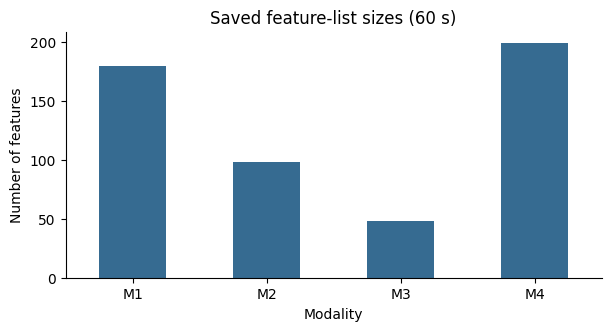

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.2), layout='constrained')
feature_counts[60].plot.bar(ax=ax, color='#366b91', rot=0)
ax.set(xlabel='Modality', ylabel='Number of features', title='Saved feature-list sizes (60 s)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()
plt.close(fig)

## What this notebook established

- Window size is a sensitivity axis: the feature definition is unchanged across 5/10/30/60 s.
- The 300 s buffer is expressed in seconds, so it removes the same wall-clock span at every resolution.
- M3 is a reduced-input protocol-semantic view because the release carries no register values.
